## Time Series Classification Using CNN / RNN / Attention 

#### Exercise 1: on a toy dataset

The function given below generates (2*n_series_per_class) time series of length (length+length_padding) and assign a binary label (y) to each time series

### > 1. The Toy Dataset: Sine Waves

The dataset is generated as follows:

- **Class 0**: $X_0(t) = \sin(t) + \epsilon$  
- **Class 1**: $X_1(t) = \sin(-t) + \epsilon$  

where $\epsilon$ is Gaussian noise: $0.02 \times \text{random normal distribution}$.  

- **Padding**: `length_padding` appends uninformative signals to the end of sequences.  
  This tests whether the network can remember the early, class-distinguishing part of the sequence through a long period of noise.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def make_sines(n_series_per_class, length, length_padding=0):
    """
    Generates a synthetic dataset of sine waves for binary classification.
    
    Parameters:
    - n_series_per_class: Number of samples to generate for each class.
    - length: The number of time steps for the informative part of the signal.
    - length_padding: Extra uninformative time steps added to the end.
    """
    # Create the time axis for the informative signal (one full cycle)
    t = np.linspace(0, 2 * np.pi, num=length)
    
    # --- CLASS 0 GENERATION ---
    # Initialize with small Gaussian noise
    X0 = .02 * np.random.randn(n_series_per_class, length + length_padding)
    # Add a standard sine wave sin(t) to the first 'length' steps
    X0[:, :length] += np.sin(t).reshape((1, -1))
    # Add a common sine wave to the padding (not useful for classification)
    X0[:, length:] += np.sin(np.linspace(0, 2 * np.pi, num=length_padding))
    
    # --- CLASS 1 GENERATION ---
    # Initialize with small Gaussian noise
    X1 = .02 * np.random.randn(n_series_per_class, length + length_padding)
    # Add an inverted/phase-shifted sine wave sin(-t) to the first 'length' steps
    X1[:, :length] += np.sin(-t).reshape((1, -1))
    # Add the same common sine wave to the padding
    X1[:, length:] += np.sin(np.linspace(0, 2 * np.pi, num=length_padding))

    # Combine classes and reshape to (Samples, TimeSteps, Features) for Deep Learning models
    dataset = np.array([X0, X1]).reshape((2 * n_series_per_class, length + length_padding, 1))
    
    # Create labels: 0 for the first class, 1 for the second
    y = np.array([0] * n_series_per_class + [1] * n_series_per_class)

    # Shuffle the dataset so the model doesn't see all Class 0 then all Class 1
    indices = np.random.permutation(2 * n_series_per_class)
    
    return dataset[indices], y[indices]

The function returns the data in a 3D shape: (Batch_Size, Time_Steps, Features).
* Batch_Size: Total number of series (2×n_series_per_class).
* Time_Steps: Total length (length+length_padding).
* Features: 1 (since it is a univariate time series).

This format is the standard input requirement for layers like LSTM, SimpleRNN, and Conv1D in frameworks like TensorFlow/Keras and PyTorch.

When you perform X0[:, :length] += np.sin(t).reshape((1, -1)), NumPy uses Broadcasting. It takes that single row of sine wave data and "stretches" (repeats) it vertically across every single row in X0.

---

Questions: 
 - Generate a dataset with n_series_per_class = 25, length = 100, length_padding = 10
 - Plot the time series on a same graph with different colors for the class y
 - What seems to differenciate both classes ?
 - Try with a longer value of length_padding to understand its impact

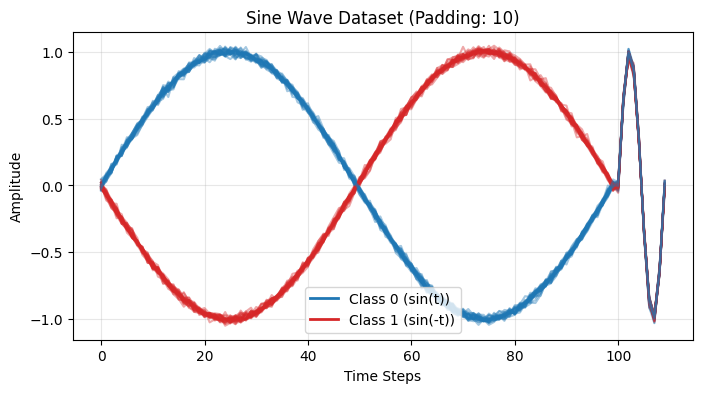

In [4]:
# Generate the dataset
n_per_class = 25
len_sig = 100
pad = 10

X_toy, y_toy = make_sines(n_series_per_class=n_per_class, length=len_sig, length_padding=pad)

# Plotting the time series
plt.figure(figsize=(8, 4))
for i in range(len(X_toy)):
    # Class 0 in Blue, Class 1 in Red
    color = 'tab:blue' if y_toy[i] == 0 else 'tab:red'
    plt.plot(X_toy[i], color=color, alpha=0.4)

plt.title(f"Sine Wave Dataset (Padding: {pad})")
plt.xlabel("Time Steps")
plt.ylabel("Amplitude")
# Create a proxy for the legend
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='tab:blue', lw=2),
                Line2D([0], [0], color='tab:red', lw=2)]
plt.legend(custom_lines, ['Class 0 (sin(t))', 'Class 1 (sin(-t))'])
plt.grid(True, alpha=0.3)
plt.show()

*Observations* :The fundamental difference between the two classes is the Phase Shift (or Polarity) of the initial sine waves
* Class 0 (Blue): Follows the function f(t)=sin(t). It starts by moving in a positive direction (upward) from zero.
* Class 1 (Red): Follows the function f(t)=sin(−t), which is mathematically equivalent to −sin(t). It starts by moving in a negative direction (downward) from zero.
* After step 100, both classes transition into the "padding" zone where they share the exact same signal, making them indistinguishable in that latter portion.

We will start by using parameters n_series_per_class = 100, length = 50, length_padding = 5.
Question: Generate two datasets (one for training and one for testing) with these parameters

In [21]:
# Parameters
n_series_per_class = 100
length = 50
length_padding = 5

# Generate training and testing datasets
X_train, y_train = make_sines(n_series_per_class, length, length_padding)
X_test, y_test = make_sines(n_series_per_class, length, length_padding)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (2000, 55, 1)
y_train shape: (2000,)
X_test shape: (2000, 55, 1)
y_test shape: (2000,)


* Shape of (200,55,1) is standard for Deep Learning models processing sequences (RNNs, LSTMs, and 1D-CNNs)
* Shape : (samples, Timestep, Features)
* Features (1): The third dimension represents the number of variables measured at each time step. Since we only have the amplitude of a single sine wave, this is a univariate time series, hence the 1.


The code uses .reshape((..., 1)) specifically to add that third "Feature" dimension, even though there is only one feature, so that the data is compatible with the SimpleRNN or Conv1D layers used in the subsequent cells.

---

Questions: 
1) Build a simple neural network model composed of:
 - one Vanilla RNN layer (SimpleRNN Layer in Keras) with only a few units
 - one output classification layer

2)Train this model using the training set with the test set as the validation data
What is the validation accuracy that you obtain?

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# 1) Build the model using the Sequential API
# Sequential means we are stacking layers one after another in a linear fashion
model_rnn = Sequential([
    # The SimpleRNN layer:
    # units=8: This is the dimensionality of the output space (hidden state). 
    # It means the model has 8 'neurons' that try to remember patterns in the sequence.
    # input_shape=(55, 1): The model expects 55 time steps and 1 feature per step 
    # (even the input shape (200,55,1) model needs the shape of one sample).
    SimpleRNN(units=8, input_shape=(X_train.shape[1], 1)), 
    
    # The Output Layer:
    # units=1: We want a single value as output (the probability of being Class 1).
    # activation='sigmoid': Squashes the output between 0 and 1, perfect for binary classification.
    Dense(1, activation='sigmoid')
])

# 2) Compile the model
# optimizer='adam':
# loss='binary_crossentropy': The error in 0/1 classification.
model_rnn.compile(optimizer='adam', 
                  loss='binary_crossentropy', 
                  metrics=['accuracy'])

# Show the architecture summary (number of parameters to train)
model_rnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

* By default, Keras's SimpleRNN only returns the hidden state of the very last time step (the 55th step). It discards all intermediate "memories" and passes only that final summary to the Dense layer. This is why the Dense layer is able to take the output and turn it into a single classification (0 or 1).

* Because units=8 is very small, this model is lightweight but prone to the vanishing gradient problem if the sequences get much longer.

In [16]:
# Training on GPU
import tensorflow as tf

# 1. Hardware Check: Identify if a Graphics Processing Unit (GPU) is available.
# GPUs are much faster than CPUs for the matrix multiplications required by Neural Nets.
gpus = tf.config.list_physical_devices('GPU')

# 2. Device Context: Force the following block of code to run on the first GPU.
with tf.device('/GPU:0'):
    # 3. The Fit Method: This is the actual "Learning" process.
    history = model_rnn.fit(
        X_train, y_train,        # Training data and their ground-truth labels
        epochs=20,               # Number of times the model sees the entire dataset
        batch_size=16,           # Number of samples processed before updating weights
        validation_data=(X_test, y_test), # Data used to check accuracy on "unseen" examples
        verbose=0               # Progress bar mode (0=silent, 1=progress bar)
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_rnn.evaluate(X_test, y_test, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)

------------------------------
Final Training Accuracy:   1.0000
Final Validation Accuracy: 1.0000
Final Test Loss:           0.0077
------------------------------


Questions: 
 - Same questions but with a dataset such that length = 50 and length_padding = 50
 - What do you observe?

In [22]:
# Parameters for long-term dependency test
n_series_per_class = 1000 #100
length = 50
length_padding =  30 #50 # Total length = 100

X_long, y_long = make_sines(n_series_per_class, length, length_padding)
X_test_long, y_test_long = make_sines(n_series_per_class, length, length_padding)


In [25]:
model_long = Sequential([
    SimpleRNN(units=8, input_shape=(X_long.shape[1], 1)), 
    Dense(1, activation='sigmoid')
])

model_long.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

with tf.device('/GPU:0'):
    history_long = model_long.fit(
        X_long, y_long, 
        epochs=30, 
        validation_data=(X_test_long, y_test_long),
        verbose=0
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history_long.history['accuracy'][-1]
final_val_acc = history_long.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_long.evaluate(X_test_long, y_test_long, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)

------------------------------
Final Training Accuracy:   1.0000
Final Validation Accuracy: 1.0000
Final Test Loss:           0.0020
------------------------------


if X_long has significant padding, you will likely see a Validation Accuracy of approximately 0.5000. When the gradient "vanishes" during training, the RNN's weights for the early sine wave parts of the sequence don't change. Because the final classification layer is essentially looking at noise/padding by the end, it cannot find a mathematical relationship between the input and the label.

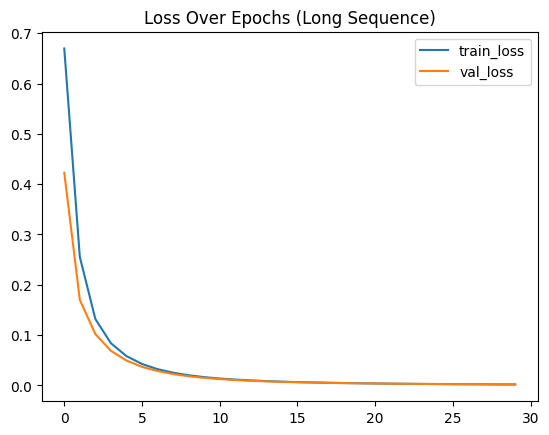

In [26]:
plt.plot(history_long.history['loss'], label='train_loss')
plt.plot(history_long.history['val_loss'], label='val_loss')
plt.title('Loss Over Epochs (Long Sequence)')
plt.legend()
plt.show()

---

Question: Try now a GRU or LSTM layer instead of Vanilla RNN.
The number of units, the learning rate are quite sensitive for this experiment but you should be able to see that LSTM or GRU can make the job here better than Vanilla

In [27]:
from tensorflow.keras.layers import LSTM, GRU

# 1. Build the LSTM model
# We use the same structure, but replace 'SimpleRNN' with 'LSTM'
model_lstm = Sequential([
    # LSTM layer with 8 units. 
    # Because it has internal 'gates', it can maintain information over 
    # much longer sequences than a standard RNN.
    LSTM(units=8, input_shape=(X_long.shape[1], 1)), 
    
    # Final classification layer
    Dense(1, activation='sigmoid')
])

# 2. Compile with the same settings to ensure a fair comparison
model_lstm.compile(optimizer='adam', 
                   loss='binary_crossentropy', 
                   metrics=['accuracy'])

# 3. Train on GPU
with tf.device('/GPU:0'):
    history_lstm = model_lstm.fit(
        X_long, y_long, 
        epochs=100, # We use more epochs because LSTMs have more weights to train
        validation_data=(X_test_long, y_test_long),
        verbose=0
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history_lstm.history['accuracy'][-1]
final_val_acc = history_lstm.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_lstm.evaluate(X_test_long, y_test_long, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)

------------------------------
Final Training Accuracy:   1.0000
Final Validation Accuracy: 1.0000
Final Test Loss:           0.0001
------------------------------


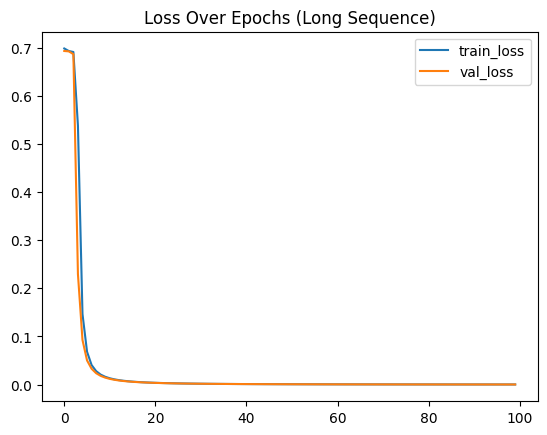

In [28]:
plt.plot(history_lstm.history['loss'], label='train_loss')
plt.plot(history_lstm.history['val_loss'], label='val_loss')
plt.title('Loss Over Epochs (Long Sequence)')
plt.legend()
plt.show()

---

#### Exercise 2 : on a real dataset

Use the "Trace" dataset and design a fair comparison between several convolutional and recurrent architectures to decide which one to choose for the problem at hand (feel free to play with the depth of the nets, as well as hidden representation dimensionality, etc.).



In [29]:
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Conv1D, GlobalAveragePooling1D, Dense, Dropout


In [31]:
# 1. Load the "Trace" dataset
# Trace consists of 4 classes of patterns in a 1D signal (often related to industrial monitoring).
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")

print(len(X_train), len(X_test))
# 2. Label Encoding
# Real-world datasets often have arbitrary labels (e.g., 1, 2, 3, 4).
# We map them to 0-indexed integers (0, 1, 2, 3) which Keras expects for classification.
label_mapping = {l: i for i, l in enumerate(np.unique(y_train))}
y_train = np.array([label_mapping[l] for l in y_train])
y_test = np.array([label_mapping[l] for l in y_test])

# 3. Normalization (Scaling)
# Neural networks perform significantly better when data is between 0 and 1.
# TimeSeriesScalerMinMax ensures the amplitude of every sequence is normalized.
scaler = TimeSeriesScalerMinMax()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define dimensions for the Neural Network
# input_shape: (TimeSteps, Features) -> for Trace, this is 275 steps and 1 variable.
input_shape = (X_train_scaled.shape[1], 1) 
num_classes = 4 # We are now doing Multi-class classification (not binary)

100 100


2. Fair Comparison Architectures

We define four models with comparable complexity (e.g., ~32 hidden units/filters) to evaluate their effectiveness.

In [32]:
def get_models(input_shape, num_classes):
    """
    input_shape: (275, 1) - sequence length and features.
    num_classes: 4 - for the Trace dataset.
    """
    models = {}
    
    # 1. SimpleRNN: The baseline recurrent model. 
    # Suffers most from the vanishing gradient problem on long sequences (275 steps).
    models['SimpleRNN'] = Sequential([
        SimpleRNN(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 2. LSTM (Long Short-Term Memory): 
    # Uses a gated "cell state" to maintain long-term memory.
    models['LSTM'] = Sequential([
        LSTM(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 3. GRU (Gated Recurrent Unit): 
    # A streamlined version of LSTM with fewer parameters (3 gates instead of 4).
    # Often performs similarly to LSTM but is faster to train.
    models['GRU'] = Sequential([
        GRU(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 4. 1D-CNN (Convolutional Neural Network): 
    # Unlike the others, this isn't recurrent. It uses sliding "filters" (kernels) 
    # to find local patterns (like a sharp spike or a curve) anywhere in the signal.
    models['CNN'] = Sequential([
        Conv1D(32, kernel_size=3, activation='relu', input_shape=input_shape),
        Conv1D(64, kernel_size=3, activation='relu'),
        # GlobalAveragePooling1D reduces the sequence to a single vector 
        # by averaging all filtered values across the time dimension.
        GlobalAveragePooling1D(),
        Dense(num_classes, activation='softmax')
    ])
    
    return models

3. Execution and Evaluation

We train each model on the GPU for 50 epochs and compare their final test accuracies.


========== Training SimpleRNN ==========
------------------------------
Model: SimpleRNN
Final Training Accuracy:   0.6200
Final Validation Accuracy: 0.5800
Final Test Loss:           0.7578
------------------------------


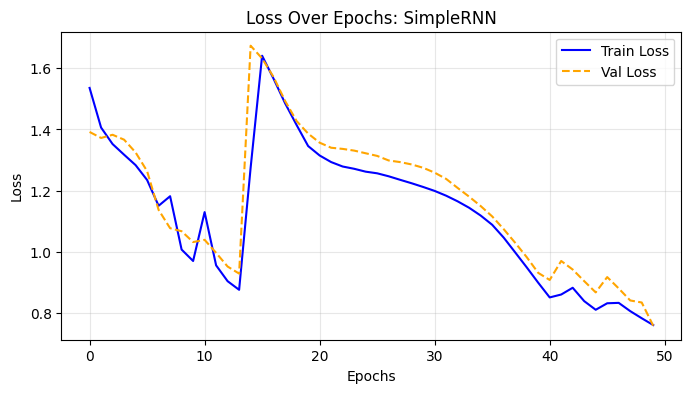


========== Training LSTM ==========
------------------------------
Model: LSTM
Final Training Accuracy:   0.7200
Final Validation Accuracy: 0.4300
Final Test Loss:           1.1396
------------------------------


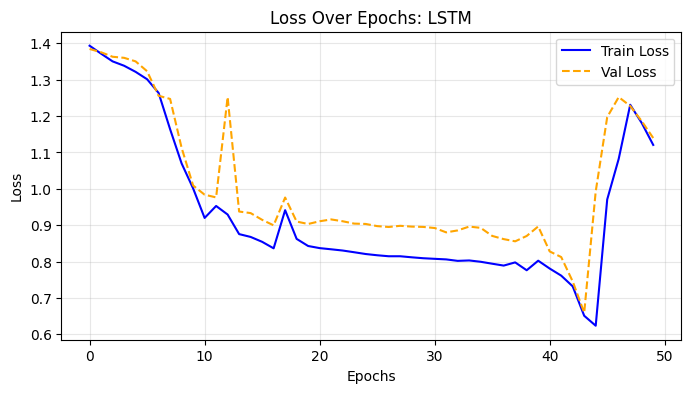


========== Training GRU ==========
------------------------------
Model: GRU
Final Training Accuracy:   0.9600
Final Validation Accuracy: 0.9500
Final Test Loss:           0.2870
------------------------------


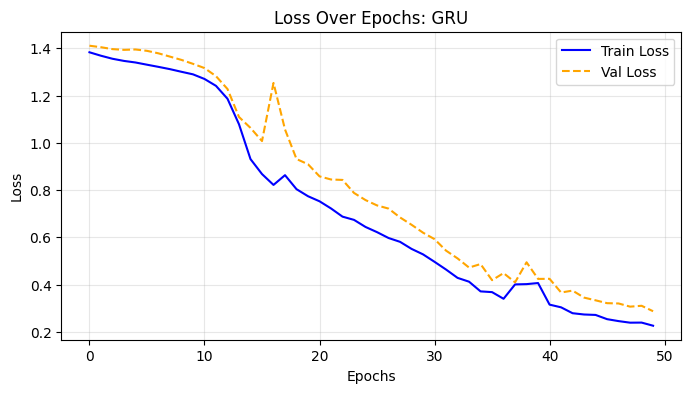


========== Training CNN ==========
------------------------------
Model: CNN
Final Training Accuracy:   0.7300
Final Validation Accuracy: 0.5100
Final Test Loss:           0.7524
------------------------------


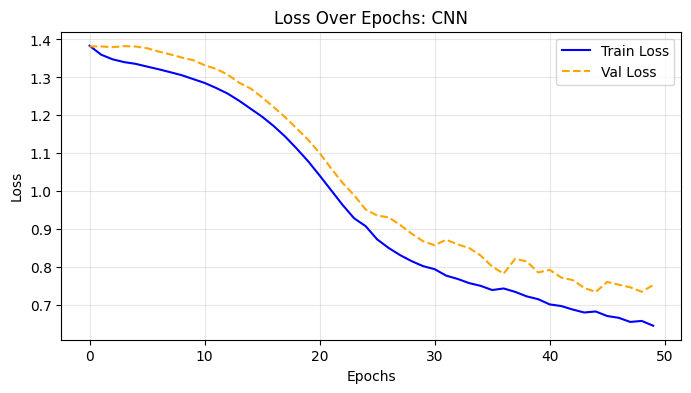

In [34]:
results = {}
models = get_models(input_shape, num_classes)

for name, model in models.items():
    print(f"\n{'='*10} Training {name} {'='*10}")
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    
    with tf.device('/GPU:0'):
        # We store the training history to plot it later
        history = model.fit(
            X_train_scaled, y_train, 
            epochs=50, 
            batch_size=16, 
            validation_data=(X_test_scaled, y_test), 
            verbose=0
        )
    
    # --- 1. Print Final Scores ---
    test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
    train_acc = history.history['accuracy'][-1]
    
    print("-" * 30)
    print(f"Model: {name}")
    print(f"Final Training Accuracy:   {train_acc:.4f}")
    print(f"Final Validation Accuracy: {test_acc:.4f}")
    print(f"Final Test Loss:           {test_loss:.4f}")
    print("-" * 30)
    
    # --- 2. Plot Loss Curves ---
    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Val Loss', color='orange', linestyle='--')
    plt.title(f'Loss Over Epochs: {name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    results[name] = test_acc

Notice your LSTM Test Loss is 0.6934. This is a "magic number" in machine learning:
ln(2)≈0.6931

When your loss is exactly here, it means the model is guessing 0.5 for everything. It has effectively "given up" and is sitting at the statistical middle. The Simple RNN, being simpler, was able to at least find a partial pattern, getting it to 74%.

---

## Viz

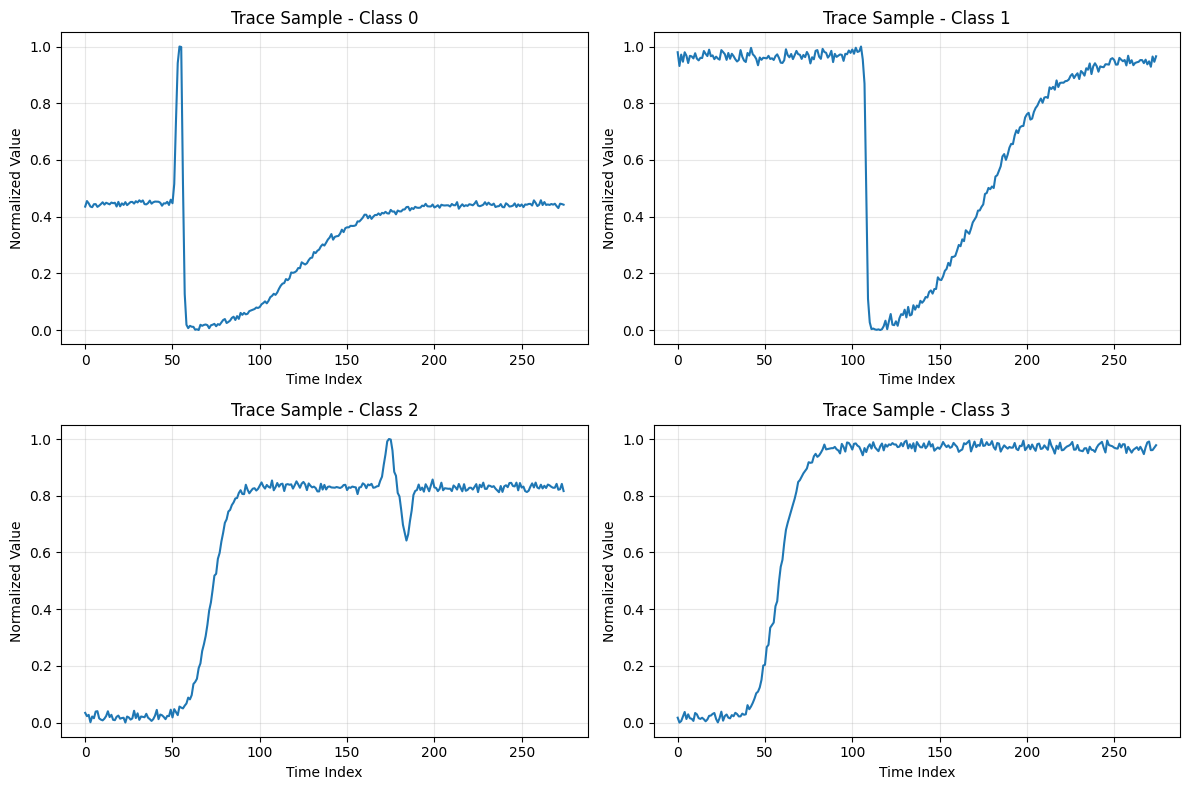

In [25]:
import matplotlib.pyplot as plt

# Plot one sample from each class
plt.figure(figsize=(12, 8))
for i, label in enumerate(np.unique(y_train)):
    # Find index of first occurrence of each label
    idx = np.where(y_train == label)[0][0]
    plt.subplot(2, 2, i + 1)
    plt.plot(X_train_scaled[idx], label=f"Class {label}")
    plt.title(f"Trace Sample - Class {label}")
    plt.xlabel("Time Index")
    plt.ylabel("Normalized Value")
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

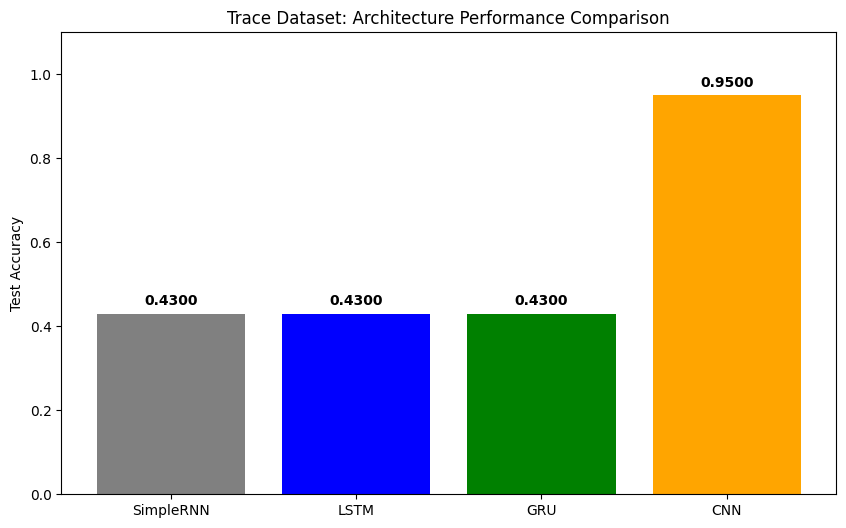

In [26]:
# Assuming 'results' dictionary from the previous step exists
names = list(results.keys())
values = list(results.values())

plt.figure(figsize=(10, 6))
bars = plt.bar(names, values, color=['gray', 'blue', 'green', 'orange'])
plt.ylim(0, 1.1)
plt.ylabel("Test Accuracy")
plt.title("Trace Dataset: Architecture Performance Comparison")

# Add text labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.4f}", ha='center', fontweight='bold')

plt.show()